# STATS 201 · Causal machine learning
**Week 4 · November 16, 2026**

**Question.** Would robot assistance improve a workcell’s inspection quality score? These instructor-created **synthetic** examples are inspired by the Kunshan visit. The score is illustrative. The data contain no host or student records.

1. Make an initial claim on the A4 worksheet.
2. Run the default cells. Join the assigned role and change **one** input in the configuration cell.
3. Rerun. Keep the opening judgment, one inline result, and one fact that would change what you can claim.

The economist route studies binary **adoption** in a panel. The computer scientist route studies a **one-unit change in assistance intensity** in a separate one-time sample. These effects answer different questions. In the simulator, the code supplies both potential outcomes. For an actual workcell we normally observe the outcome under the treatment it received. A hypothesis about the sign of the effect still needs evidence.

**Colab** [Open the Week 4 lab](https://colab.research.google.com/github/sunshineluyao/ml4ss/blob/main/modules/05-causal-inference/week04_causal_ml.ipynb). Choose **Runtime → Run all** on a standard CPU runtime. Use **File → Save a copy in Drive** to keep your changes. All results print or plot inline. The saved outputs show the default run.

## Starting questions

Last week the robot classifier learned from an observed completion label and scored held-out examples. Its score estimates how likely completion is under observed inputs. This week we ask what would happen if we changed assistance. Two causal stories can fit the same observations and imply different responses to an intervention.

| Role | Target | What makes the contrast causal? |
|---|---|---|
| Economist | Effect of adoption on adopting workcells, in score points | A credible comparison trend for the adopters without treatment, no anticipation, no spillovers, and comparable measurements |
| Computer scientist | Mean effect of increasing assistance by one unit of the standardized dose scale | A defensible causal graph and sufficient pre-treatment variables to adjust for |

In [1]:
import itertools
import numpy as np
import pandas as pd
from scipy import stats
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt

# Change ONE setting, then rerun all cells. Keep the seed for comparison.
SEED = 201
TRUE_EFFECT = 3.0
TREND_BIAS = 0.0       # Economist: try 1.5
TIMING = "baseline"    # Computer scientist: try "ordered"
HIDDEN_STRENGTH = 0.0  # Optional after locking TIMING to "ordered": try 0.9

if TIMING not in {"baseline", "ordered"}:
    raise ValueError('Set TIMING to "baseline" or "ordered".')

## A · Economist route · Difference-in-differences

The panel contains 200 simulated workcells observed for four periods, with no missing data. Periods −2 and −1 precede adoption. Adoption begins at period 0. Period 1 is visible in the plot. For the primary comparison we use −1 and 0. Normal draws are independent. The same workcell baseline enters its four observations.

- $X_i$ (product mix), $a_i$ (baseline shock), and $\eta_i$ (adoption shock) are standard normal. $G_i=1[0.8X_i+\eta_i>0]$ marks adopting workcells.
- Baseline $B_i=70+3X_i+2G_i+2a_i$. A period shock $\epsilon_{it}$ is standard normal.
- $Y_{it}=B_i+1.2t+\delta G_it+\tau G_i1[t\ge0]+\epsilon_{it}$. $\delta$ is `TREND_BIAS` and $\tau$ is `TRUE_EFFECT`. Scores are in points on an illustrative continuous scale.

**Identification.** Under parallel untreated trends, the control group’s change approximates what adopting workcells would have experienced without adoption. A placebo before adoption can detect a difference in trends. A small placebo leaves post-adoption parallel trends uncertain.

$$\widehat{\mathrm{ATT}}=(\bar Y_{G=1,t=0}-\bar Y_{G=1,t=-1})-(\bar Y_{G=0,t=0}-\bar Y_{G=0,t=-1}).$$

**Pseudocode**

    Select adopting and comparison workcells.
    Calculate a before-to-after score change for each cell.
    Subtract the mean comparison change from the mean adopter change.
    Repeat for two pre-adoption periods as a placebo.
    Compare with the simulator’s true effect and explain an assumption.

In [2]:
rng = np.random.default_rng(SEED)
n_cells = 200
mix, baseline_shock, adopt_shock = rng.standard_normal((3, n_cells))
group = (0.8 * mix + adopt_shock > 0).astype(int)
base = 70 + 3 * mix + 2 * group + 2 * baseline_shock
times = np.array([-2, -1, 0, 1])
period_shock = rng.standard_normal((n_cells, len(times)))
y_panel = (base[:, None] + 1.2 * times + TREND_BIAS * group[:, None] * times
           + TRUE_EFFECT * group[:, None] * (times >= 0) + period_shock)
panel = pd.DataFrame({
    "cell": np.repeat(np.arange(n_cells), len(times)),
    "period": np.tile(times, n_cells),
    "adopter": np.repeat(group, len(times)),
    "active": (group[:, None] * (times >= 0)).ravel(),
    "score": y_panel.ravel(),
})
print("Panel sample · one row per workcell and period")
print(panel.head().round(2).to_string(index=False))


def mean_change_difference(first, second):
    before, after = list(times).index(first), list(times).index(second)
    changes = y_panel[:, after] - y_panel[:, before]
    adopters = changes[group == 1]
    comparisons = changes[group == 0]
    estimate = adopters.mean() - comparisons.mean()
    av, cv = adopters.var(ddof=1) / len(adopters), comparisons.var(ddof=1) / len(comparisons)
    dof = (av + cv)**2 / (av**2 / (len(adopters) - 1) + cv**2 / (len(comparisons) - 1))
    margin = stats.t.ppf(0.975, dof) * np.sqrt(av + cv)
    return estimate, estimate - margin, estimate + margin


did = mean_change_difference(-1, 0)
placebo = mean_change_difference(-2, -1)
panel_means = panel.pivot_table(index="period", columns="adopter", values="score")
print("\nGroup means · score points")
print(panel_means.rename(columns={0:"Comparison", 1:"Adopters"}).round(2).to_string())
print(f"\nAdoption contrast: {did[0]:.2f} points, 95% interval [{did[1]:.2f}, {did[2]:.2f}]")
print(f"Pre-adoption placebo: {placebo[0]:.2f}, interval [{placebo[1]:.2f}, {placebo[2]:.2f}]")
print(f"Known synthetic adoption effect: {TRUE_EFFECT:.2f} points")

Panel sample · one row per workcell and period
 cell  period  adopter  active  score
    0      -2        1       0  73.91
    0      -1        1       0  77.34
    0       0        1       1  80.28
    0       1        1       1  80.28
    1      -2        1       0  66.41

Group means · score points
adopter  Comparison  Adopters
period                       
-2            66.69     70.74
-1            67.83     72.17
 0            68.98     76.10
 1            70.03     77.38

Adoption contrast: 2.78 points, 95% interval [2.39, 3.17]
Pre-adoption placebo: 0.29, interval [-0.10, 0.67]
Known synthetic adoption effect: 3.00 points


**Reading the output.** The four means for periods −1 and 0 form the estimate. The interval applies a Welch two-sample calculation to one change per independent workcell. It describes sampling uncertainty for the contrast. A biased contrast can have a narrow interval. In real data, shared shocks or rollout at the factory level can require different inference. Change `TREND_BIAS` from 0 to 1.5. Explain what happens to the adoption and placebo contrasts. Name one real record that could reveal a different trend or simultaneous change.

## B · Computer scientist route · Causal discovery and estimation

The unit is a workcell in a separate sample of 1,800 simulated cells. $X$ is pre-treatment product mix, $T$ an assistance dose standardized to SD 1, and $Y$ the inspection score. $U$ is a hidden scheduling factor. The exogenous terms are independent standard normal and there are no missing data.

$$D^*=0.7X+hU+\epsilon_T,\quad T=\frac{D^*}{\sqrt{0.7^2+h^2+1}},\quad
Y=70+\tau T+1.8X+2hU+2\epsilon_Y.$$

Discovery sees $X,T,Y$. $h$ is `HIDDEN_STRENGTH`. The simulator’s effect per dose-scale unit is $\tau$. `TIMING` changes the analyst’s information and leaves the observations unchanged.

**Identification.** Use marginal and partial-correlation tests in this linear-Gaussian example. Find the directed acyclic graphs that agree with the tests and supplied timing. This is an exhaustive three-variable teaching analogue of constraint-based discovery. When $X$ blocks the common-cause path and the graph has no omitted confounders, we can estimate the mean score under an intervention:

$$E[Y\mid do(T=t)]=\int E[Y\mid T=t,X=x]\,dP(x).$$

Here the code uses the dose coefficient in an additive linear model. The alternative graph places $Y$ upstream of $T$ with no causal path from $T$ to $Y$. The dose effect in that graph is zero.

**Pseudocode**

    Test independence for each pair, with and without conditioning on the third variable.
    Keep acyclic graphs with compatible independence patterns.
    Restrict the arrows using the timing supplied by the analyst.
    Estimate under each surviving graph and report the ambiguity.
    Specify the field evidence that could distinguish the graphs.

Discovery relies on credible timing, acyclicity, the causal Markov and faithfulness assumptions, usable independence tests, and no omitted common causes or selection for this exercise. Faithfulness means that distinct causal paths do not happen to cancel the dependencies expected from the graph.

In [3]:
rng = np.random.default_rng(SEED + 1)
n_obs = 1800
x, hidden, dose_shock, score_shock = rng.standard_normal((4, n_obs))
h = HIDDEN_STRENGTH
dose = (0.7*x + h*hidden + dose_shock) / np.sqrt(0.7**2 + h**2 + 1)
score = 70 + TRUE_EFFECT*dose + 1.8*x + 2*h*hidden + 2*score_shock
obs = pd.DataFrame({"X": x, "T": dose, "Y": score})
print("Observed sample · one workcell per row")
print(obs.head().round(2).to_string(index=False))
nodes = tuple(obs.columns)
pairs = list(itertools.combinations(nodes, 2))


def independent_in_graph(edges, a, b, conditioning):
    if (a, b) in edges or (b, a) in edges:
        return False
    middle = next(node for node in nodes if node not in {a, b})
    via_middle = all((node, middle) in edges or (middle, node) in edges for node in (a, b))
    if not via_middle:
        return True
    collider = (a, middle) in edges and (b, middle) in edges
    return (conditioning != middle) if collider else (conditioning == middle)


def observed_tests(alpha=0.01):
    rows = []
    for a, b in pairs:
        middle = next(node for node in nodes if node not in {a, b})
        for c in (None, middle):
            values = obs[[a, b]].to_numpy()
            if c is not None:
                covariate = obs[[c]].to_numpy()
                values = values - LinearRegression().fit(covariate, values).predict(covariate)
            r = np.corrcoef(values.T)[0, 1]
            dof = len(values) - 2 - int(c is not None)
            test_statistic = r * np.sqrt(dof / max(1 - r*r, np.finfo(float).eps))
            p_value = 2 * stats.t.sf(abs(test_statistic), dof)
            rows.append((a, b, c, r, p_value, p_value >= alpha))
    return rows


def admissible_graphs(tests):
    compatible = []
    forbidden = {("T", "X"), ("Y", "X")}
    if TIMING == "ordered":
        forbidden.add(("Y", "T"))
    for states in itertools.product((0, 1, -1), repeat=len(pairs)):
        edges = {pair if state > 0 else pair[::-1]
                 for pair, state in zip(pairs, states) if state}
        # A directed cycle on exactly three nodes requires every node to have an outgoing edge.
        if edges & forbidden or all(any(start == node for start, _ in edges) for node in nodes):
            continue
        if all(independent_in_graph(edges, a, b, c) == possible_zero
               for a, b, c, _, _, possible_zero in tests):
            compatible.append(edges)
    return compatible


tests = observed_tests()
print("\nPairwise tests · alpha = 0.01")
test_table = pd.DataFrame(tests, columns=["A", "B", "Given", "r", "p", "compatible with zero"])
print(test_table.to_string(index=False, formatters={"r": "{:.2f}".format, "p": "{:.2g}".format}))
graphs = admissible_graphs(tests)
slope = LinearRegression().fit(obs[["T", "X"]], obs["Y"]).coef_[0]
print(f"\nTiming: {TIMING}. Compatible graphs: {len(graphs)}")
if not graphs:
    print("No exact match. Revisit sampling error, testing threshold, variables and timing.")
for graph in graphs:
    graph_text = ", ".join(f"{a} → {b}" for a, b in sorted(graph)) or "no edges"
    # X precedes T and Y. Thus T → Y is the only possible directed path from T to Y.
    model_effect = slope if ("T", "Y") in graph else 0.0
    print(f"  {graph_text} | implied effect {model_effect:.2f} points per dose unit")
print(f"Known synthetic dose effect: {TRUE_EFFECT:.2f} points per dose unit")

train, test = train_test_split(obs, test_size=0.25, random_state=SEED)
y_hat = LinearRegression().fit(train[["T", "X"]], train["Y"]).predict(test[["T", "X"]])
mae = mean_absolute_error(test["Y"], y_hat)
base_mae = mean_absolute_error(test["Y"], np.full(len(test), train["Y"].median()))
print(f"\nPrediction MAE on {len(test)} held-out cells: {mae:.2f} points, median baseline: {base_mae:.2f}")

Observed sample · one workcell per row
    X     T     Y
 1.81  1.01 78.02
-0.73  0.07 68.70
-1.09 -0.97 66.40
-0.40 -0.36 65.10
-1.15  0.03 68.05

Pairwise tests · alpha = 0.01
A B Given     r        p  compatible with zero
X T  None  0.57 8.3e-153                 False
X T     Y -0.16  5.2e-12                 False
X Y  None  0.74 3.6e-311                 False
X Y     T  0.59   1e-170                 False
T Y  None  0.84        0                 False
T Y     X  0.77        0                 False

Timing: baseline. Compatible graphs: 2
  T → Y, X → T, X → Y | implied effect 2.99 points per dose unit
  X → T, X → Y, Y → T | implied effect 0.00 points per dose unit
Known synthetic dose effect: 3.00 points per dose unit

Prediction MAE on 450 held-out cells: 1.62 points, median baseline: 3.86


**Reading the output.** Both timing-compatible graphs fit the default tests. A large p-value means the test did not detect a nonzero correlation at this threshold. Set `TIMING="ordered"` to supply the additional claim that assistance precedes the score. The eligible effect changes because of the added timing information. Optional: increase the hidden factor with timing fixed. A correct time order leaves room for an unmeasured common cause.

The last line evaluates prediction using **observed** scores in held-out workcells. Mean absolute error (MAE) is the average absolute error in score points. Lower is better on the same cases. Timing alone keeps the data and MAE identical, even when it restricts the causal answers.

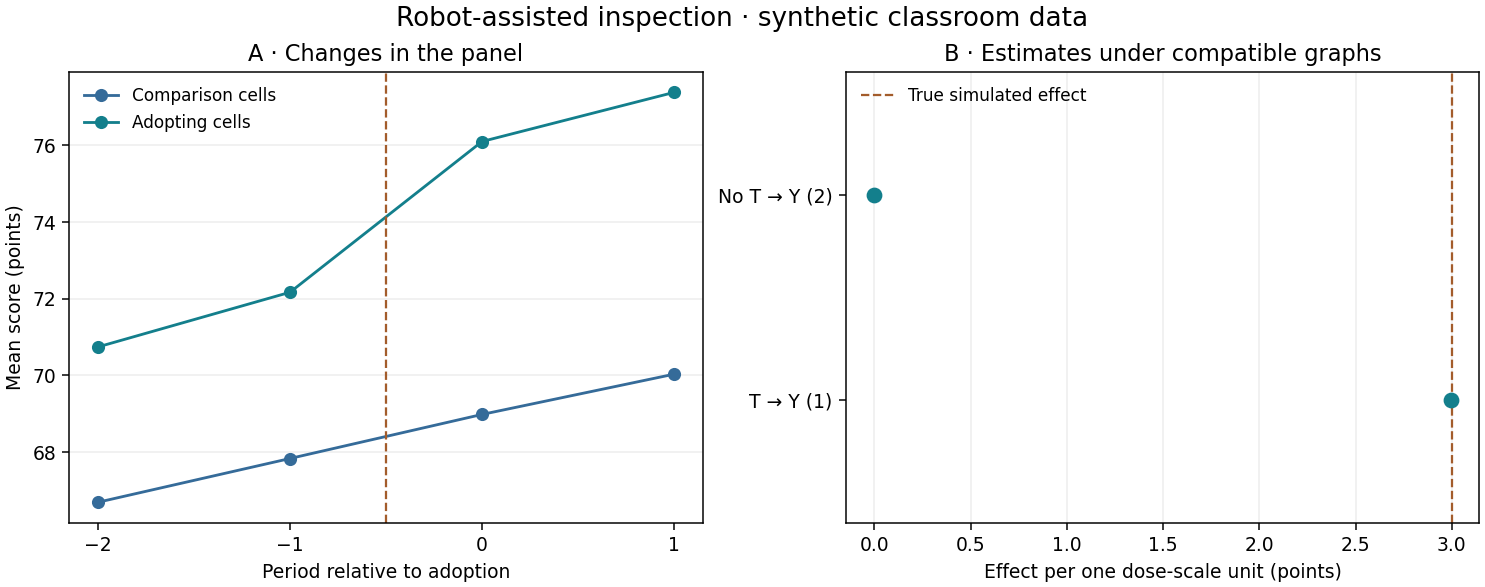

In [4]:
fig, (left, right) = plt.subplots(1, 2, figsize=(11, 4.35), layout="constrained")
colors = ["#356B99", "#137F8C"]
for index, name in enumerate(["Comparison cells", "Adopting cells"]):
    left.plot(times, panel_means[index], color=colors[index], marker="o", label=name)
left.axvline(-0.5, linestyle="--", color="#a35c2b", lw=1.2)
left.set(xticks=times, xlabel="Period relative to adoption", ylabel="Mean score (points)",
         title="A · Changes in the panel")
left.legend(frameon=False, fontsize=9)
left.grid(axis="y", alpha=0.22)
if graphs:
    values = [slope if ("T", "Y") in graph else 0.0 for graph in graphs]
    heights = np.arange(len(graphs))
    names = [("T → Y" if ("T", "Y") in graph else "No T → Y") + f" ({i+1})"
             for i, graph in enumerate(graphs)]
    right.scatter(values, heights, color="#137F8C", s=55, zorder=3)
    right.set_yticks(heights, names)
    right.set_ylim(-0.6, len(graphs)-0.4)
else:
    right.text(0.5, 0.5, "No compatible graph", ha="center", va="center", transform=right.transAxes)
    right.set_yticks([])
right.axvline(TRUE_EFFECT, linestyle="--", color="#a35c2b", lw=1.2, label="True simulated effect")
right.set(xlabel="Effect per one dose-scale unit (points)", title="B · Estimates under compatible graphs")
right.legend(frameon=False, fontsize=9)
right.grid(axis="x", alpha=0.22)
fig.suptitle("Robot-assisted inspection · synthetic classroom data", fontsize=14)
plt.show()

## Two-minute report

**Economists.** “For adopting workcells, our contrast changed from ___ to ___ points (new 95% interval ___). The placebo was ___. The assumption that matters is ___. A record we would seek is ___.”

**Computer scientists.** “Our graph set changed from ___ to ___ when we supplied ___. The implied effect(s) were ___ points per dose-scale unit. Held-out MAE was ___. The next fact we need is ___.”

Each group shows one panel or output table. Reply individually on Ed with your setting, a result and units, an assumption challenged by the other group, and a check for your own study. Share a view link to your copy if available.

### Python toolkit

- **This lab** uses NumPy, pandas, SciPy, scikit-learn, and Matplotlib.
- **Design and estimation:** [statsmodels](https://www.statsmodels.org/stable/) for regression and appropriate covariance, [rdrobust](https://rdpackages.github.io/rdrobust/) for local RD, and [DoubleML](https://docs.doubleml.org/stable/guide/models.html) for cross-fitted nuisance estimation under a stated design.
- **Discovery and graphs:** [causal-learn](https://causal-learn.readthedocs.io/en/latest/) for PC/FCI, and [DoWhy](https://www.pywhy.org/dowhy/main/) for specifying, identifying, estimating and checking an effect under a graph. The lab runs with the core packages above.

### Sources

- Royal Swedish Academy of Sciences. (2021). [The Prize in Economic Sciences 2021](https://www.nobelprize.org/uploads/2021/10/press-economicsciencesprize2021-2.pdf).
- Card, D., & Krueger, A. B. (1994). Minimum wages and employment: A case study of the fast-food industry in New Jersey and Pennsylvania. *American Economic Review, 84*(4), 772–793. [Authors' working paper](https://www.nber.org/papers/w4509).
- Association for Computing Machinery. (2011). [A.M. Turing Award recipient Judea Pearl](https://amturing.acm.org/award_winners/pearl_2658896.cfm).
- Pearl, J. (2009). Causal inference in statistics: An overview. *Statistics Surveys, 3*, 96–146. [DOI](https://doi.org/10.1214/09-SS057).
- Kalisch, M., & Bühlmann, P. (2007). Estimating high-dimensional directed acyclic graphs with the PC-algorithm. *Journal of Machine Learning Research, 8*, 613–636. [Article](https://www.jmlr.org/papers/v8/kalisch07a.html).